# Assignment 1 - Building a Vision Model with Keras

In this assignment, you will build a simple vision model using Keras. The goal is to classify images from the Fashion MNIST dataset, which contains images of clothing items.

You will:
1. Load and inspect the Fashion MNIST dataset.
2. Run a simple baseline model to establish a performance benchmark.
3. Build and evaluate a simple CNN model, choosing appropriate loss and metrics.
4. Design and run controlled experiments on one hyperparameter (e.g., number of filters, kernel size, etc.) and one regularization technique (e.g., dropout, L2 regularization).
5. Analyze the results and visualize the model's performance.

# 1. Loading and Inspecting the Dataset

Fashion MNIST is a dataset of grayscale images of clothing items, with 10 classes. Each image is 28x28 pixels, like the MNIST dataset of handwritten digits. Keras provides a convenient way to load this dataset. 

In this section, you should:

- [ ] Inspect the shapes of the training and test sets to confirm their size and structure.
- [ ] Convert the labels to one-hot encoded format if necessary. (There is a utility function in Keras for this.)
- [ ] Visualize a few images from the dataset to understand what the data looks like.

In [9]:

import tensorflow as tf
from tensorflow.keras.datasets import fashion_mnist
(X_train, y_train), (X_test, y_test) = fashion_mnist.load_data()

# Normalize the pixel values to be between 0 and 1
X_train = X_train.astype('float32') / 255.0
X_test = X_test.astype('float32') / 255.0

# Classes in the Fashion MNIST dataset
class_names = ["T-shirt/top", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"]

In [10]:
# Inspect the shapes of the datasets

print(f"X_train shape: {X_train.shape}, y_train shape: {y_train.shape}")
print(f"X_test shape:  {X_test.shape}, y_test shape:  {y_test.shape}")

# Convert labels to one-hot encoding
from tensorflow.keras.utils import to_categorical

num_classes = 10
y_train_cat = to_categorical(y_train, num_classes=num_classes)
y_test_cat = to_categorical(y_test, num_classes=num_classes)

print("encoded y_train shape:", y_train_cat.shape)
print("encoded y_test shape: ", y_test_cat.shape)

X_train shape: (60000, 28, 28), y_train shape: (60000,)
X_test shape:  (10000, 28, 28), y_test shape:  (10000,)
encoded y_train shape: (60000, 10)
encoded y_test shape:  (10000, 10)


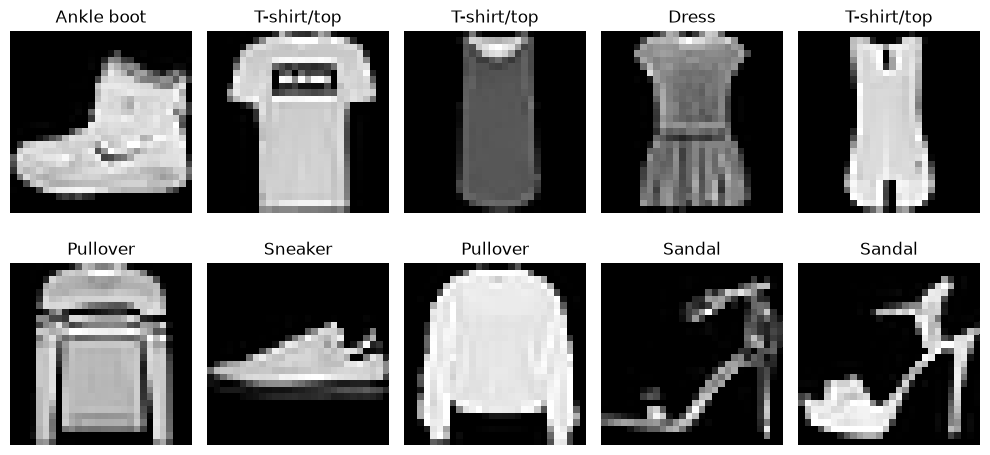

In [11]:
import matplotlib.pyplot as plt
# Verify the data looks as expected

plt.figure(figsize=(10, 5))
for i in range(10):
    plt.subplot(2, 5, i + 1)
    plt.imshow(X_train[i], cmap='gray')
    plt.title(class_names[y_train[i]])
    plt.axis('off')

plt.tight_layout()
plt.show()

Reflection: Does the data look as expected? How is the quality of the images? Are there any issues with the dataset that you notice?

**Your answer here**

The data looks quite appealing, particularly the cloth images. The accuracy of nomencleture of all clothes seems close to 80-90%, though there are some repeatations in couple of items i.e. sandal and t-shirt/top. These redundancies could be create some ambiguity in sorting varities, for instance plain and stripped pullovers.

# 2. Baseline Model

In this section, you will create a linear regression model as a baseline. This model will not use any convolutional layers, but it will help you understand the performance of a simple model on this dataset.
You should:
- [ ] Create a simple linear regression model using Keras.
- [ ] Compile the model with an appropriate loss function and optimizer.
- [ ] Train the model on the training set and evaluate it on the test set.

A linear regression model can be created using the `Sequential` API in Keras. Using a single `Dense` layer with no activation function is equivalent to a simple linear regression model. Make sure that the number of units in the output layer matches the number of classes in the dataset.

Note that for this step, we will need to use `Flatten` to convert the 2D images into 1D vectors before passing them to the model. Put a `Flatten()` layer as the first layer in your model so that the 2D image data can be flattened into 1D vectors.

In [17]:
from keras.models import Sequential
from keras.layers import Dense, Flatten

# Create a simple linear regression model
model = Sequential()

# You can use `model.add(<layer>)` to add layers to the model
model.add(Flatten(input_shape=(28, 28)))
model.add(Dense(10, activation=None))

# Compile the model using `model.compile()`
model.compile(
    optimizer='sgd',
    loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True),
    metrics=['accuracy']
)

# Train the model with `model.fit()`
history = model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

# Evaluate the model with `model.evaluate()`
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f"Test Loss in percentage: {test_loss*100:.2f}")
print(f"Test Accuracy in percentage: {test_acc*100:.2f}")

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 8s 5ms/step - accuracy: 0.7253 - loss: 0.8679 - val_accuracy: 0.7840 - val_loss: 0.6588
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.7998 - loss: 0.6176 - val_accuracy: 0.8074 - val_loss: 0.5803
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 12s 6ms/step - accuracy: 0.8167 - loss: 0.5626 - val_accuracy: 0.8185 - val_loss: 0.5437
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.8259 - loss: 0.5330 - val_accuracy: 0.8233 - val_loss: 0.5259
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.8306 - loss: 0.5135 - val_accuracy: 0.8257 - val_loss: 0.5099
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 10s 6ms/step - accuracy: 0.8332 - loss: 0.4997 - val_accuracy: 0.8328 - val_loss: 0.4976
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 6s 4ms/step - accuracy: 0.8359 - loss: 0.4887 - val_accuracy: 0.8321 - val_loss: 0.4915
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - accuracy: 0.8396 - loss: 0.479

Reflection: What is the performance of the baseline model? How does it compare to what you expected? Why do you think the performance is at this level?

**Your answer here**

When it comes to the performance of the baseline model,the accuracy of test is 83.06% which is quite good within my predicted range. Based on 10 epoch sampling classes, the performance is exceedingly well based on linear classifier. Though, performance might be lagging behind other modern neural networks.

# 3. Building and Evaluating a Simple CNN Model

In this section, you will build a simple Convolutional Neural Network (CNN) model using Keras. A convolutional neural network is a type of deep learning model that is particularly effective for image classification tasks. Unlike the basic neural networks we have built in the labs, CNNs can accept images as input without needing to flatten them into vectors.

You should:
- [ ] Build a simple CNN model with at least one convolutional layer (to learn spatial hierarchies in images) and one fully connected layer (to make predictions).
- [ ] Compile the model with an appropriate loss function and metrics for a multi-class classification problem.
- [ ] Train the model on the training set and evaluate it on the test set.

Convolutional layers are designed to accept inputs with three dimensions: height, width and channels (e.g., RGB for color images). For grayscale images like those in Fashion MNIST, the input shape will be (28, 28, 1).

When you progress from the convolutional layers to the fully connected layers, you will need to flatten the output of the convolutional layers. This can be done using the `Flatten` layer in Keras, which doesn't require any parameters.

In [20]:
from keras.layers import Conv2D

# Reshape the data to include the channel dimension
X_train = X_train.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

# Create a simple CNN model
model = Sequential()
model.add(Conv2D(32, kernel_size=(3, 3), activation='relu', input_shape=(28, 28, 1)))
model.add(Flatten())
model.add(Dense(10, activation='softmax'))

# Compile the model
model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# Train the model
history = model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=32,
    validation_split=0.2
)

# Evaluate the model
test_loss, test_acc = model.evaluate(X_test, y_test)
print(f"Test Loss in percentage: {test_loss*100:.2f}")
print(f"Test Accuracy in percentage: {test_acc*100:.2f}")

Epoch 1/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 20s 12ms/step - accuracy: 0.8524 - loss: 0.4228 - val_accuracy: 0.8867 - val_loss: 0.3193
Epoch 2/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 18s 12ms/step - accuracy: 0.8956 - loss: 0.2916 - val_accuracy: 0.8900 - val_loss: 0.3087
Epoch 3/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.9092 - loss: 0.2525 - val_accuracy: 0.8967 - val_loss: 0.2899
Epoch 4/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 22s 13ms/step - accuracy: 0.9195 - loss: 0.2243 - val_accuracy: 0.8976 - val_loss: 0.2903
Epoch 5/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 19s 13ms/step - accuracy: 0.9286 - loss: 0.2007 - val_accuracy: 0.9011 - val_loss: 0.2945
Epoch 6/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 18s 12ms/step - accuracy: 0.9344 - loss: 0.1823 - val_accuracy: 0.8935 - val_loss: 0.3093
Epoch 7/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.9414 - loss: 0.1632 - val_accuracy: 0.9007 - val_loss: 0.2987
Epoch 8/10
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 19s 12ms/step - accuracy: 0.9465 -

Reflection: Did the CNN model perform better than the baseline model? If so, by how much? What do you think contributed to this improvement?

**Your answer here**

As predicted, CNN model outperformed the baseline model. In percentage it outperformed by 6.59%. The difference lies in terms of spatial locality. CNN uses convolutional filters which slide across small localized patches where as baseline model uses 28*28 image and converts to 784 array values which destroys neighbouring relationships with pixels.

# 3. Designing and Running Controlled Experiments

In this section, you will design and run controlled experiments to improve the model's performance. You will focus on one hyperparameter and one regularization technique.
You should:
- [ ] Choose one hyperparameter to experiment with (e.g., number of filters, kernel size, number of layers, etc.) and one regularization technique (e.g., dropout, L2 regularization). For your hyperparameter, you should choose at least three different values to test (but there is no upper limit). For your regularization technique, simply test the presence or absence of the technique.
- [ ] Run experiments by modifying the model architecture or hyperparameters, and evaluate the performance of each model on the test set.
- [ ] Record the results of your experiments, including the test accuracy and any other relevant metrics.
- [ ] Visualize the results of your experiments using plots or tables to compare the performance of different models.

The best way to run your experiments is to create a `for` loop that iterates over a range of values for the hyperparameter you are testing. For example, if you are testing different numbers of filters, you can create a loop that runs the model with 32, 64, and 128 filters. Within the loop, you can compile and train the model, then evaluate it on the test set. After each iteration, you can store the results in a list or a dictionary for later analysis.

Note: It's critical that you re-initialize the model (by creating a new instance of the model) before each experiment. If you don't, the model will retain the weights from the previous experiment, which can lead to misleading results.


--- Training CNN with 32 filters ---


c:\Users\User\Desktop\DSI\ML repos\deep_learning\deep-learning-env\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 14s 16ms/step - accuracy: 0.8452 - loss: 0.4450 - val_accuracy: 0.8788 - val_loss: 0.3456
Epoch 2/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 22s 18ms/step - accuracy: 0.8913 - loss: 0.3076 - val_accuracy: 0.8869 - val_loss: 0.3138
Epoch 3/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step - accuracy: 0.9041 - loss: 0.2685 - val_accuracy: 0.8907 - val_loss: 0.3052
Epoch 4/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 12s 15ms/step - accuracy: 0.9136 - loss: 0.2415 - val_accuracy: 0.8973 - val_loss: 0.2934
Epoch 5/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 11s 15ms/step - accuracy: 0.9213 - loss: 0.2200 - val_accuracy: 0.9010 - val_loss: 0.2866

--- Training CNN with 64 filters ---
Epoch 1/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 24s 28ms/step - accuracy: 0.8524 - loss: 0.4216 - val_accuracy: 0.8823 - val_loss: 0.3304
Epoch 2/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 21s 28ms/step - accuracy: 0.8965 - loss: 0.2898 - val_accuracy: 0.8921 - val_loss: 0.2996
Epoch 3/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 20s 26ms/step - accu

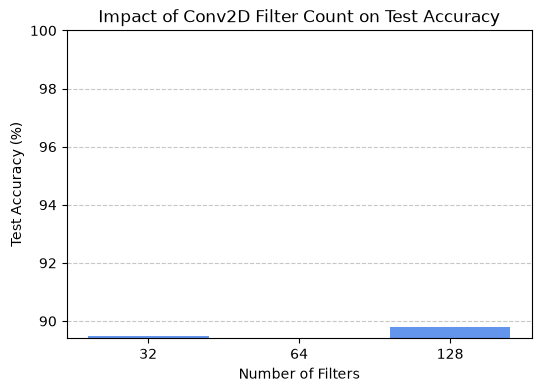

In [8]:
# A. Test Hyperparameters
import tensorflow as tf
from tensorflow.keras.datasets import fashion_mnist
import pandas as pd
import matplotlib.pyplot as plt
from keras.models import Sequential
from keras.layers import Conv2D, Flatten, Dense

# 1. Ensure dataset is loaded
(x_train_raw, y_train), (x_test_raw, y_test) = fashion_mnist.load_data()
X_train = (x_train_raw.astype('float32') / 255.0).reshape(-1, 28, 28, 1)
X_test = (x_test_raw.astype('float32') / 255.0).reshape(-1, 28, 28, 1)

# 2. Run hyperparameter loop
filter_options = [32, 64, 128]
hyperparam_results = []

for num_filters in filter_options:
    print(f"\n--- Training CNN with {num_filters} filters ---")
    
    model = Sequential([
        Conv2D(num_filters, kernel_size=(3, 3), activation='relu', input_shape=(28, 28, 1)),
        Flatten(),
        Dense(10, activation='softmax')
    ])
    
    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    
    model.fit(
        X_train, y_train,
        epochs=5,
        batch_size=64,
        validation_split=0.2,
        verbose=1
    )
    
    test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
    hyperparam_results.append({
        'Number of Filters': num_filters,
        'Test Loss': round(test_loss, 4),
        'Test Accuracy in percentage': round(test_acc*100, 4)
    })

# Summary table and plot
df_hyperparams = pd.DataFrame(hyperparam_results)
print("\nHyperparameter Experiment Summary:")
print(df_hyperparams)

plt.figure(figsize=(6, 4))
plt.bar([str(f) for f in df_hyperparams['Number of Filters']], df_hyperparams['Test Accuracy in percentage'], color='cornflowerblue')
plt.xlabel('Number of Filters')
plt.ylabel('Test Accuracy (%)')
plt.title('Impact of Conv2D Filter Count on Test Accuracy')
plt.ylim(min(df_hyperparams['Test Accuracy in percentage']) - 0.02, 100)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()


--- Running: No Regularization (Baseline) ---


c:\Users\User\Desktop\DSI\ML repos\deep_learning\deep-learning-env\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 26s 31ms/step - accuracy: 0.8494 - loss: 0.4300 - val_accuracy: 0.8762 - val_loss: 0.3502
Epoch 2/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 22s 29ms/step - accuracy: 0.8958 - loss: 0.2946 - val_accuracy: 0.8861 - val_loss: 0.3171
Epoch 3/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 21s 28ms/step - accuracy: 0.9089 - loss: 0.2530 - val_accuracy: 0.8974 - val_loss: 0.2891
Epoch 4/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 22s 29ms/step - accuracy: 0.9195 - loss: 0.2233 - val_accuracy: 0.8947 - val_loss: 0.2969
Epoch 5/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 43s 32ms/step - accuracy: 0.9284 - loss: 0.2005 - val_accuracy: 0.9047 - val_loss: 0.2819

--- Running: With Dropout (0.25) ---
Epoch 1/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 44s 53ms/step - accuracy: 0.8475 - loss: 0.4339 - val_accuracy: 0.8807 - val_loss: 0.3395
Epoch 2/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 36s 47ms/step - accuracy: 0.8937 - loss: 0.3004 - val_accuracy: 0.8875 - val_loss: 0.3089
Epoch 3/5
750/750 ━━━━━━━━━━━━━━━━━━━━ 43s 50ms/step - accu

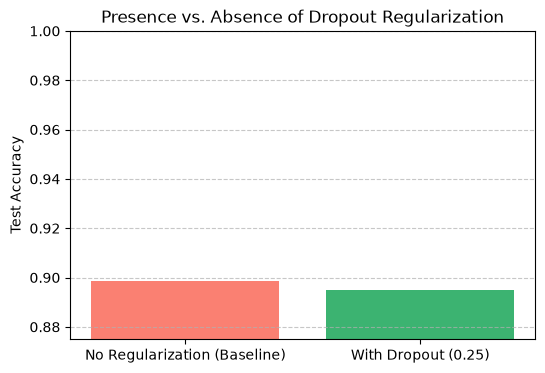

In [3]:
# B. Test presence or absence of regularization
from keras.layers import Dropout

regularization_experiments = {
    'No Regularization (Baseline)': False,
    'With Dropout (0.25)': True
}

reg_results = []

for label, use_dropout in regularization_experiments.items():
    print(f"\n--- Running: {label} ---")
    
    # 1. Re-initialize the model instance
    model = Sequential()
    model.add(Conv2D(64, kernel_size=(3, 3), activation='relu', input_shape=(28, 28, 1)))
    
    if use_dropout:
        model.add(Dropout(0.25))
        
    model.add(Flatten())
    model.add(Dense(10, activation='softmax'))
    
    # 2. Compile
    model.compile(
        optimizer='adam',
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )
    
    # 3. Train
    model.fit(
        X_train, y_train,
        epochs=5,
        batch_size=64,
        validation_split=0.2,
        verbose=1
    )
    
    # 4. Evaluate on test set
    test_loss, test_acc = model.evaluate(X_test, y_test, verbose=0)
    reg_results.append({
        'Experiment': label,
        'Test Loss': round(test_loss, 4),
        'Test Accuracy': round(test_acc, 4)
    })

# Tabular comparison
df_reg = pd.DataFrame(reg_results)
print("\nRegularization Experiment Summary:")
print(df_reg)

# Plot comparison
plt.figure(figsize=(6, 4))
plt.bar(df_reg['Experiment'], df_reg['Test Accuracy'], color=['salmon', 'mediumseagreen'])
plt.ylabel('Test Accuracy')
plt.title('Presence vs. Absence of Dropout Regularization')
plt.ylim(min(df_reg['Test Accuracy']) - 0.02, 1.0)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()

Reflection: Report on the performance of the models you tested. Did any of the changes you made improve the model's performance? If so, which ones? What do you think contributed to these improvements? Finally, what combination of hyperparameters and regularization techniques yielded the best performance?

**Your answer here**

With baseline, it achieved the test accuracy of 89.84% and with dropout it achieved the test accuracy of 89.51%.
No regulaization model marginally outperformed by 0.33% as compared to dropout model.
I believe the network contains only a single convolutional layer before flattening, which led to this improvement. Also, With only 5 training epochs, the baseline model was not yet severely overfit, meaning Dropout model got slight underfitting.


# 5. Training Final Model and Evaluation

In this section, you will train the final model using the best hyperparameters and regularization techniques you found in the previous section. You should:
- [ ] Compile the final model with the best hyperparameters and regularization techniques.
- [ ] Train the final model on the training set and evaluate it on the test set.
- [ ] Report the final model's performance on the test set, including accuracy and any other relevant metrics.

In [10]:
import numpy as np
from keras.models import Sequential
from keras.layers import Conv2D, Flatten, Dense
# Define the Fashion-MNIST class labels
class_names = [
    "T-shirt/top", "Trouser", "Pullover", "Dress", "Coat",
    "Sandal", "Shirt", "Sneaker", "Bag", "Ankle boot"
]

# Run the classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=class_names))
from sklearn.metrics import classification_report, confusion_matrix

# 1. Build the final model using best hyperparameters
final_model = Sequential([
    Conv2D(64, kernel_size=(3, 3), activation='relu', input_shape=(28, 28, 1)),
    Flatten(),
    Dense(10, activation='softmax')
])

# 2. Compile the model
final_model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

# 3. Train the model 
history = final_model.fit(
    X_train, y_train,
    epochs=10,
    batch_size=64,
    validation_split=0.2,
    verbose=1
)

# 4. Evaluate on the test set
test_loss, test_accuracy = final_model.evaluate(X_test, y_test, verbose=0)
print(f"\nFinal Test Loss:     {test_loss:.4f}")
print(f"Final Test Accuracy: {test_accuracy*100:.2f}%")

# 5. Additional metrics: Detailed classification report
y_pred_probs = final_model.predict(X_test)
y_pred = np.argmax(y_pred_probs, axis=1)

print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=class_names))


Classification Report:
              precision    recall  f1-score   support

 T-shirt/top       0.85      0.84      0.84      1000
     Trouser       0.99      0.97      0.98      1000
    Pullover       0.86      0.83      0.84      1000
       Dress       0.89      0.91      0.90      1000
        Coat       0.84      0.85      0.85      1000
      Sandal       0.98      0.97      0.98      1000
       Shirt       0.73      0.75      0.74      1000
     Sneaker       0.95      0.97      0.96      1000
         Bag       0.97      0.97      0.97      1000
  Ankle boot       0.97      0.96      0.97      1000

    accuracy                           0.90     10000
   macro avg       0.90      0.90      0.90     10000
weighted avg       0.90      0.90      0.90     10000



c:\Users\User\Desktop\DSI\ML repos\deep_learning\deep-learning-env\Lib\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 23s 26ms/step - accuracy: 0.8472 - loss: 0.4324 - val_accuracy: 0.8757 - val_loss: 0.3405
Epoch 2/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 20s 25ms/step - accuracy: 0.8960 - loss: 0.2945 - val_accuracy: 0.8874 - val_loss: 0.3105
Epoch 3/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 22s 27ms/step - accuracy: 0.9092 - loss: 0.2542 - val_accuracy: 0.8903 - val_loss: 0.3048
Epoch 4/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 20s 27ms/step - accuracy: 0.9187 - loss: 0.2260 - val_accuracy: 0.8997 - val_loss: 0.2848
Epoch 5/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 20s 26ms/step - accuracy: 0.9269 - loss: 0.2030 - val_accuracy: 0.9042 - val_loss: 0.2806
Epoch 6/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 24s 30ms/step - accuracy: 0.9340 - loss: 0.1835 - val_accuracy: 0.8997 - val_loss: 0.2934
Epoch 7/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 20s 26ms/step - accuracy: 0.9409 - loss: 0.1672 - val_accuracy: 0.9028 - val_loss: 0.2899
Epoch 8/10
750/750 ━━━━━━━━━━━━━━━━━━━━ 23s 29ms/step - accuracy: 0.9442 - loss: 0.1556 - 

Reflection: How does the final model's performance compare to the baseline and the CNN model? What do you think contributed to the final model's performance? If you had time, what other experiments would you run to further improve the model's performance?

**Your answer here**

The final model performance exceeded compared to both baseline(considerably) and the CNN model(slightly) at flat 90%. 2D convolutional grid allowed better image recognition of cloth and footware features which contributed to this performance. I'd experiment by adding multiple convolutions gradually to see how image recognition and thus accuracy improves to measure model's performance.

🚨 **Please review our [Assignment Submission Guide](https://github.com/UofT-DSI/onboarding/blob/main/onboarding_documents/submissions.md)** 🚨 for detailed instructions on how to format, branch, and submit your work. Following these guidelines is crucial for your submissions to be evaluated correctly.
### Submission Parameters:
* Submission Due Date: `23:59 PM - 26/10/2025`
* The branch name for your repo should be: `assignment-1`
* What to submit for this assignment:
    * This Jupyter Notebook (assignment_1.ipynb)
    * The Lab 1 notebook (labs/lab_1.ipynb)
    * The Lab 2 notebook (labs/lab_2.ipynb)
    * The Lab 3 notebook (labs/lab_3.ipynb)
* What the pull request link should look like for this assignment: `https://github.com/<your_github_username>/deep_learning/pull/<pr_id>`
* Open a private window in your browser. Copy and paste the link to your pull request into the address bar. Make sure you can see your pull request properly. This helps the technical facilitator and learning support staff review your submission easily.
Checklist:
- [ ] Created a branch with the correct naming convention.
- [ ] Ensured that the repository is public.
- [ ] Reviewed the PR description guidelines and adhered to them.
- [ ] Verify that the link is accessible in a private browser window.
If you encounter any difficulties or have questions, please don't hesitate to reach out to our team via our Slack at `#cohort-7-help-ml`. Our Technical Facilitators and Learning Support staff are here to help you navigate any challenges.